<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install kagglehub

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV

In [18]:
path = kagglehub.dataset_download("radheshyamkollipara/bank-customer-churn")
df = pd.read_csv(path + "/Customer-Churn-Records.csv")
df.head()

Using Colab cache for faster access to the 'bank-customer-churn' dataset.


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


Аналіз даних

In [19]:
print(df.shape)
print(df.isna().sum().sum(), "пропусків")
print(df["Exited"].value_counts(normalize=True))

(10000, 18)
0 пропусків
Exited
0    0.7962
1    0.2038
Name: proportion, dtype: float64


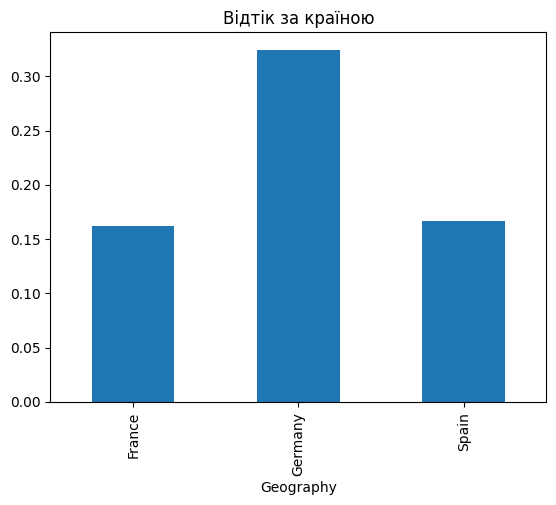

In [20]:
df.groupby("Geography")["Exited"].mean().plot(kind="bar", title="Відтік за країною")
plt.show()

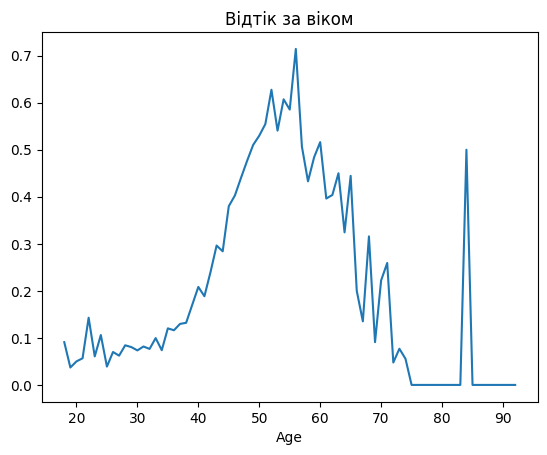

In [21]:
df.groupby("Age")["Exited"].mean().plot(title="Відтік за віком")
plt.show()

Моделі

In [22]:
df=df.drop(columns=["RowNumber", "CustomerId", "Surname", "Complain"])
df=pd.get_dummies(df,drop_first=True)

X=df.drop(columns="Exited")
y=df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.transform(X_test)

In [23]:
models={
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results=[]
for name, model in models.items():
  model.fit(X_train_s, y_train)
  pred=model.predict(X_test_s)
  proba=model.predict_proba(X_test_s)[:, 1]
  results.append([name, accuracy_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, proba)])

pd.DataFrame(results, columns=["Модель", "Точність", "F1", "ROC AUC"])

,Модель,Точність,F1,ROC AUC
0,Logistic Regression,0.8130,0.315018,0.778356
1,Random Forest,0.8685,0.596006,0.864665
2,Gradient Boosting,0.8720,0.619048,0.876760


In [25]:
params={
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    'max_depth':[2,3,4],
}

grid=GridSearchCV(GradientBoostingClassifier(random_state=42), params, scoring="roc_auc", cv=3)
grid.fit(X_train_s, y_train)


best=grid.best_estimator_
print(grid.best_params_)
print("точність:", accuracy_score(y_test, best.predict(X_test_s)))
print("F1:", f1_score(y_test, best.predict(X_test_s)))
print("ROC-AUC:", roc_auc_score(y_test, best.predict_proba(X_test_s)[:, 1]))

{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
точність: 0.8705
F1: 0.6151560178306092
ROC-AUC: 0.8769429254113706


Тест

In [26]:
client = {
    "CreditScore":600,
    "Geography":"Germany",       # France/Spain/Germany
    "Gender":"Female",
    "Age":45,
    "Tenure":3,
    "Balance":120000,
    "NumOfProducts":1,
    "HasCrCard":1,
    "IsActiveMember":0,
    "EstimatedSalary":80000,
    "Satisfaction Score":3,
    "Card Type":"GOLD",          # DIAMOND/GOLD/SILVER/PLATINUM
    "Point Earned":400,
}

In [27]:
c = pd.get_dummies(pd.DataFrame([client]))
c = c.reindex(columns=X.columns, fill_value=0)

pred = best.predict(scaler.transform(c))[0]
proba = best.predict_proba(scaler.transform(c))[0, 1]

print("Піде" if pred == 1 else "Залишиться", f"(ймовірність відтоку: {proba:.2f})")

Піде (ймовірність відтоку: 0.76)


Висновок: у результаті Logistic Regression показала найгірший результат. Random forest набагато краще, тоді як Gradient boosting є найкращою за всіма 3 показниками(його і обрано). Підбір параметрів майже не вплинув на результати. Для тестової клієнти модель обрала відмову, що в цілому адекватний результат.